[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_00/MFM_ch0_romania/MFM_ch0_romania.ipynb)

# MFM_ch0_romania

**Modelling Financial Markets (MFM) — Chapter 0: Financial Markets in 2026**

The Romanian market: BET-TR and BVB blue chips (dividend-adjusted) since 2015, the EUR/RON BNR reference rate since the 2005 redenomination, and Romanian versus German 10-year government yields; plus a data-quality check of EUR/RON bad ticks.

*Author: Daniel Traian Pele*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_0'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


In [2]:
import os
import io
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

## Style and data loader

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Chart colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def bottom_legend(fig, ncol=3, handles=None, labels=None, fontsize=8):
    """Legend below the figure (outside the axes), after tight_layout; save_fig keeps it (bbox_inches='tight')."""
    plt.tight_layout()
    if handles is None:
        handles, labels, seen = [], [], set()
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in seen and not l.startswith('_'):
                    handles.append(h); labels.append(l); seen.add(l)
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=ncol, frameon=False, fontsize=fontsize)


def log_axis(ax, ticks):
    """Log axis with readable labels (no scientific notation)."""
    ax.set_yscale('log')
    ax.set_yticks(ticks)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_minor_formatter(plt.NullFormatter())


In [4]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
LOCAL_DIRS = ['../../../data/market', '../../data/market', '../data/market', 'data/market']   # cloned repository
START, END = '2000-01-01', '2026-09-18'

# name -> (source, symbol, field)
SERIES = {
    'S&P 500': ('market', 'GSPC.INDX', 'close'),
    'Euro Stoxx 50': ('market', 'STOXX50E.INDX', 'close'),
    'Nikkei 225': ('market', 'N225.INDX', 'close'),
    'VIX': ('market', 'VIX.INDX', 'close'),
    'BET-TR': ('market', 'BETTR.INDX', 'close'),
    'BET': ('market', 'BET', 'close'),
    'BET-XT': ('market', 'BETXT.INDX', 'close'),
    'US Treasuries 20y+ (TLT)': ('market', 'TLT.US', 'adjusted_close'),
    'SPY': ('market', 'SPY.US', 'adjusted_close'),
    'RSP': ('market', 'RSP.US', 'adjusted_close'),
    'IBIT': ('market', 'IBIT.US', 'close'),
    'IBIT volume': ('market', 'IBIT.US', 'volume'),
    'Gold': ('market', 'XAUUSD.FOREX', 'close'),
    'EUR/USD': ('market', 'EURUSD.FOREX', 'close'),
    'EUR/RON (EODHD)': ('market', 'EURRON.FOREX', 'close'),
    'EUR/RON (market)': ('market', 'EURRON.FOREX', 'close'),
    'Bitcoin': ('market', 'BTC-USD.CC', 'close'),
    'Ethereum': ('market', 'ETH-USD.CC', 'close'),
    'Tether (USDT)': ('market', 'USDT-USD.CC', 'close'),
    'Romania 10y': ('market', 'RO10Y.GBOND', 'close'),
    'Germany 10y': ('market', 'DE10Y.GBOND', 'close'),
    'Banca Transilvania': ('market', 'TLV.RO', 'adjusted_close'),
    'OMV Petrom': ('market', 'SNP.RO', 'adjusted_close'),
    'BRD': ('market', 'BRD.RO', 'adjusted_close'),
    'Transgaz': ('market', 'TGN.RO', 'adjusted_close'),
    'Romgaz': ('market', 'SNG.RO', 'adjusted_close'),
    'Hidroelectrica': ('market', 'H2O.RO', 'adjusted_close'),
    'EUR/RON': ('bnr', 'EUR', None),
    'DGS10': ('fred', 'DGS10', None),
    'DGS2': ('fred', 'DGS2', None),
    'FEDFUNDS': ('fred', 'FEDFUNDS', None),
    'USD per EUR': ('fred', 'DEXUSEU', None),
    'JPY per USD': ('fred', 'DEXJPUS', None),
    'T10Y2Y': ('fred', 'T10Y2Y', None),
    'ETF equities': ('fred', 'BOGZ1LM563064100Q', None),
    'All equities': ('fred', 'BOGZ1LM893064105Q', None),
    'Stablecoins': ('defillama', 'stablecoincharts/all', None),
}
WEEKDAYS_ONLY = {'EUR/USD', 'Gold'}


def read_market(symbol):
    """Daily market series: local copy if the repository is cloned, otherwise GitHub."""
    for d in LOCAL_DIRS:
        path = os.path.join(d, f'{symbol}.csv')
        if os.path.exists(path):
            return pd.read_csv(path, index_col='date', parse_dates=True)
    return pd.read_csv(REPO_RAW + f'{symbol}.csv', index_col='date', parse_dates=True)


def fetch_daily(symbol, source='market', field='close', start=START, end=END):
    """Single access point to the data: returns a daily pd.Series (no NaN)."""
    if source == 'market':
        s = read_market(symbol)[field]
    elif source == 'fred':
        raw = urllib.request.urlopen(
            f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={symbol}', timeout=90).read().decode()
        s = pd.read_csv(io.StringIO(raw), index_col=0, parse_dates=True, na_values='.').iloc[:, 0]
    elif source == 'defillama':
        req = urllib.request.Request(f'https://stablecoins.llama.fi/{symbol}',
                                     headers={'User-Agent': 'Mozilla/5.0'})
        d = json.load(urllib.request.urlopen(req, timeout=90))
        s = pd.Series({pd.to_datetime(int(x['date']), unit='s'): x['totalCirculatingUSD'].get('peggedUSD', 0)
                       for x in d}) / 1e9                                   # billion USD
    elif source == 'bnr':
        # official BNR rate (RON per unit of currency), yearly XML archives
        import re
        rows = []
        for y in range(max(int(start[:4]), 2005), int(end[:4]) + 1):
            url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
            xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                         timeout=90).read().decode()
            for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
                m = re.search(rf'<Rate currency="{symbol}">([\d.]+)</Rate>', body)
                if m:
                    rows.append((d, float(m.group(1))))
        s = pd.Series(dict(rows))
    else:
        raise ValueError(f'unknown source: {source}')
    s = pd.to_numeric(s, errors='coerce')
    s.index = pd.to_datetime(s.index)
    s.index.name = 'Date'
    return s.sort_index().loc[start:end].dropna()


def load(name, start=START, end=END):
    """The series named in SERIES (gold and EUR/USD: weekdays only)."""
    source, symbol, field = SERIES[name]
    s = fetch_daily(symbol, source, field, start, end).rename(name)
    if name in WEEKDAYS_ONLY:
        s = s[s.index.dayofweek < 5]
    return s


def load_panel(names, start=START, end=END):
    """Several series aligned on date (NaN where a market does not trade)."""
    return pd.concat([load(n, start, end) for n in names], axis=1)


## Helper functions

In [5]:
def ann_stats(p, periods=252):
    """Annualised return (CAGR) and annualised volatility from daily prices.

    periods='obs' uses the observed number of observations per year of the series.
    """
    p = p.dropna()
    years = (p.index[-1] - p.index[0]).days / 365.25
    cagr = (p.iloc[-1] / p.iloc[0]) ** (1 / years) - 1
    r = np.log(p).diff().dropna()
    if periods == 'obs':
        periods = len(r) / years
    return cagr, r.std() * np.sqrt(periods)


def clean_series(y, max_dev=1.0, window=11):
    """Drop weekend rows and points more than max_dev from the centred rolling median."""
    y = y[y.index.dayofweek < 5]
    med = y.rolling(window, center=True, min_periods=3).median()
    return y[(y - med).abs() <= max_dev]

## Data

In [6]:
px = load_panel(['BET-TR'])
bvb = load_panel(['Banca Transilvania', 'OMV Petrom', 'BRD', 'Transgaz', 'Romgaz', 'Hidroelectrica'])
eurron = load('EUR/RON')
eurron_mkt = load('EUR/RON (EODHD)')
bonds = load_panel(['Romania 10y', 'Germany 10y'])

## Charts

In [7]:
def fig_romania():
    """BET-TR and BVB blue chips (dividend-adjusted), EUR/RON (BNR), 10-year yields Romania vs Germany."""
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5), gridspec_kw={'width_ratios': [1.35, 0.9, 0.9]})
    start = '2015-01-05'
    out = {}
    b = px['BET-TR'].loc[start:].dropna()
    axes[0].plot(b.index, b / b.iloc[0], color='black', lw=1.1, label=f'BET-TR x{b.iloc[-1] / b.iloc[0]:.1f}')
    out['BET-TR'] = b.iloc[-1] / b.iloc[0]
    for n, c in zip(['Banca Transilvania', 'OMV Petrom', 'BRD', 'Transgaz', 'Romgaz'],
                    [MainBlue, Amber, Forest, Purple, Orange]):
        s_ = bvb[n].loc[start:].dropna()
        g = s_ / s_.iloc[0]
        out[n] = g.iloc[-1]
        axes[0].plot(g.index, g.values, color=c, lw=0.6, label=f'{n.split()[0]} x{g.iloc[-1]:.1f}')
    log_axis(axes[0], [0.5, 1, 2, 4, 8, 16])
    axes[0].set_ylabel('Growth of 1 RON (log)')
    axes[0].set_title('BET-TR and blue chips since 2015', fontsize=8, loc='left')
    axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=6, frameon=False)
    fx = eurron.loc['2005-07-01':]
    axes[1].plot(fx.index, fx.values, color=IDAred, lw=0.7)
    axes[1].set_title('EUR/RON (BNR)', fontsize=8, loc='left')
    y = pd.concat([clean_series(bonds[c].dropna()) for c in bonds], axis=1).dropna()
    axes[2].plot(y.index, y['Romania 10y'], color=MainBlue, lw=0.7, label='Romania (bonds in RON)')
    axes[2].plot(y.index, y['Germany 10y'], color=IDAred, lw=0.7, label='Germany (bonds in EUR)')
    axes[2].set_title('10-year yields (%)', fontsize=8, loc='left')
    axes[2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=6, frameon=False)
    for ax in axes:
        ax.tick_params(axis='x', labelsize=7)
        ax.xaxis.set_major_locator(mdates.YearLocator(4 if ax is axes[0] else 6))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    save_fig('ch0_romania')
    r_fx = np.log(fx).diff().dropna()
    spread = (y['Romania 10y'] - y['Germany 10y'])
    return dict(growth=out, bettr_first=b.index[0].date(), eurron_first=fx.iloc[0], eurron_first_date=fx.index[0].date(),
                eurron_last=fx.iloc[-1], eurron_last_date=fx.index[-1].date(),
                eurron_vol_2015_26=ann_stats(fx.loc['2015':], 'obs')[1],
                ro10y_last=y['Romania 10y'].iloc[-1], de10y_last=y['Germany 10y'].iloc[-1],
                spread_last=spread.iloc[-1], spread_max=spread.max(), spread_max_date=spread.idxmax().date(),
                bonds_first=y.index[0].date(), h2o_first=bvb['Hidroelectrica'].first_valid_index().date())

In [8]:
def data_pitfall():
    """EUR/RON: EODHD series (with bad ticks) vs BNR, 2015-2026."""
    r_e = np.log(eurron_mkt).diff().dropna().loc['2015':]
    r_b = np.log(eurron).diff().dropna().loc['2015':]
    top = r_e.abs().sort_values(ascending=False).head(6)
    q = lambda r: len(r) / ((r.index[-1] - r.index[0]).days / 365.25)   # observed frequency (FX: not 252)
    return dict(vol_market=r_e.std() * np.sqrt(q(r_e)), vol_bnr=r_b.std() * np.sqrt(q(r_b)),
                largest={d.date(): round(r_e.loc[d], 4) for d in top.index})

In [9]:
def fig_bad_ticks():
    """EUR/RON: EODHD series (bad ticks) vs the BNR rate, 2015-2026, with annualised volatilities."""
    mk = eurron_mkt.loc['2015':]; bn = eurron.loc['2015':]
    res = data_pitfall()
    fig, ax = plt.subplots(figsize=(6.6, 2.1))
    ax.plot(mk.index, mk.values, color=IDAred, lw=0.6,
            label=f"EODHD EUR/RON series: volatility {res['vol_market']:.1%}")
    ax.plot(bn.index, bn.values, color=MainBlue, lw=0.9, label=f"BNR reference rate: volatility {res['vol_bnr']:.1%}")
    for d, dy in [('2025-08-13', 0), ('2022-01-05', 0)]:
        t = pd.Timestamp(d)
        ax.annotate(f'{t:%d %b %Y}: {mk[t]:.2f}', (t, mk[t]), xytext=(-8, 0), textcoords='offset points', ha='right',
                    va='center', fontsize=7, color='black')
    ax.set_ylabel('RON per EUR'); ax.set_ylim(4.2, 6.05)
    ax.set_title('EUR/RON 2015-2026 from two sources', fontsize=9, loc='left')
    bottom_legend(fig, ncol=2)
    save_fig('ch0_bad_ticks')
    return res

## Run

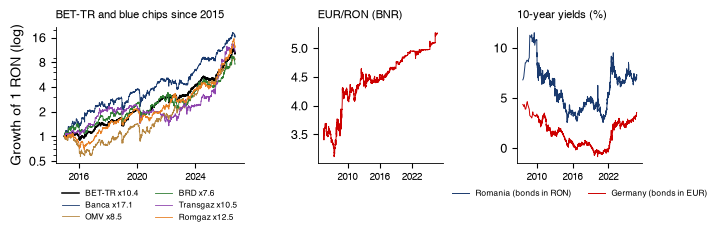

   saved ch0_romania
{'growth': {'BET-TR': np.float64(10.3853720024036), 'Banca Transilvania': np.float64(17.0911366809494), 'OMV Petrom': np.float64(8.537463976945245), 'BRD': np.float64(7.609976433621367), 'Transgaz': np.float64(10.487535966870142), 'Romgaz': np.float64(12.486343062275635)}, 'bettr_first': datetime.date(2015, 1, 5), 'eurron_first': np.float64(3.5986), 'eurron_first_date': datetime.date(2005, 7, 4), 'eurron_last': np.float64(5.2644), 'eurron_last_date': datetime.date(2026, 9, 18), 'eurron_vol_2015_26': np.float64(0.02063091162157248), 'ro10y_last': np.float64(7.33), 'de10y_last': np.float64(3.5296), 'spread_last': np.float64(3.8004000000000002), 'spread_max': np.float64(8.303), 'spread_max_date': datetime.date(2009, 3, 2), 'bonds_first': datetime.date(2007, 9, 3), 'h2o_first': datetime.date(2023, 7, 12)}


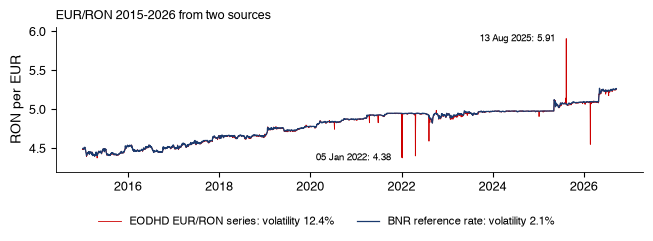

   saved ch0_bad_ticks
{'vol_market': np.float64(0.12388242455784151), 'vol_bnr': np.float64(0.020653890748372285), 'largest': {datetime.date(2025, 8, 14): np.float64(-0.1541), datetime.date(2025, 8, 13): np.float64(0.154), datetime.date(2022, 1, 7): np.float64(-0.1222), datetime.date(2022, 1, 10): np.float64(0.1219), datetime.date(2022, 1, 5): np.float64(-0.1211), datetime.date(2022, 1, 6): np.float64(0.121)}}


In [10]:
r = fig_romania()
print(r)
print(fig_bad_ticks())

![ch0_romania](./ch0_romania.png)

![ch0_bad_ticks](./ch0_bad_ticks.png)

Output: `ch0_romania.pdf`, `ch0_bad_ticks.pdf`